Cargando datos de entrenamiento...
Found 4462 files belonging to 2 classes.
Using 3570 files for training.

Cargando datos de validación...
Found 4462 files belonging to 2 classes.
Using 892 files for validation.

Clases cargadas: ['buildings', 'forest']


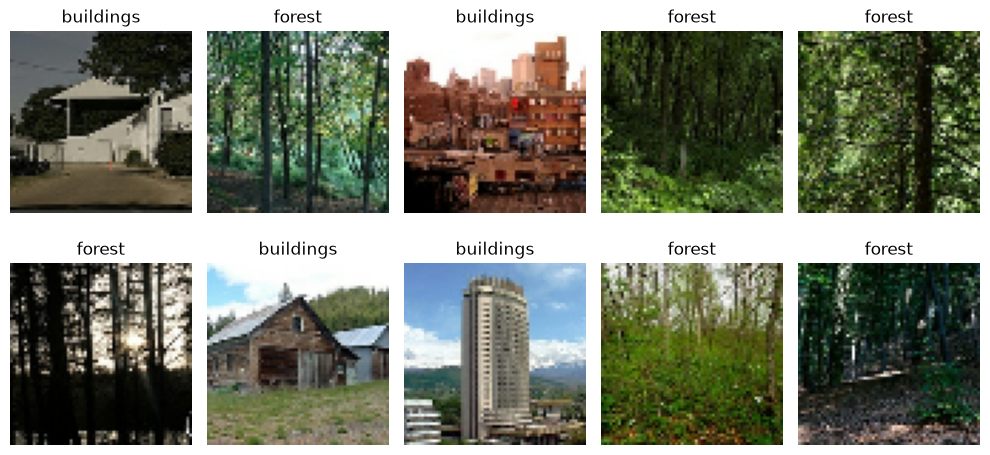

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. DEFINICIÓN DE VARIABLES Y RUTA
# Agregamos el nivel extra de la carpeta que detectó el sistema
CARPETA_DATOS = './intel/seg_train/seg_train' 

IMG_SIZE = (64, 64) 
BATCH_SIZE = 32
SEMILLA = 42 

print("Cargando datos de entrenamiento...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    CARPETA_DATOS,
    validation_split=0.2, 
    subset="training",
    seed=SEMILLA,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=['buildings', 'forest'] 
)

print("\nCargando datos de validación...")
val_dataset = tf.keras.utils.image_dataset_from_directory(
    CARPETA_DATOS,
    validation_split=0.2,
    subset="validation",
    seed=SEMILLA,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=['buildings', 'forest'] 
)

class_names = train_dataset.class_names
print(f"\nClases cargadas: {class_names}")

# 2. PREPROCESAMIENTO: Normalización (escala de 0 a 1)
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
val_dataset = val_dataset.map(lambda x, y: (normalization_layer(x), y))

# 3. VISUALIZACIÓN EXPLORATORIA
plt.figure(figsize=(10, 5))
for images, labels in train_dataset.take(1): 
    for i in range(10): 
        ax = plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy()) 
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# 4. DISEÑO DE LA ARQUITECTURA MLP
print("\nConstruyendo el modelo MLP...")

modelo_mlp = tf.keras.Sequential([
    # Aplanamos la imagen de 2D a 1D
    tf.keras.layers.Flatten(input_shape=(64, 64, 3)),
    
    # Capas ocultas con activación ReLU y Dropout para evitar que memorice (Overfitting)
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.3), 
    
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    
    # Capa de salida: 1 sola neurona con activación 'sigmoid' porque es clasificación binaria
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Mostramos un resumen de las capas
modelo_mlp.summary()

# 5. COMPILACIÓN Y ENTRENAMIENTO
print("\nCompilando el modelo...")
modelo_mlp.compile(
    optimizer='adam', # El optimizador más usado por su eficiencia
    loss='binary_crossentropy', # Función de pérdida obligatoria para problemas binarios
    metrics=['accuracy'] # Queremos medir el porcentaje de aciertos
)

EPOCAS = 10 # Puedes subirlo a 15 o 20 después si quieres probar si mejora

print("\nIniciando el entrenamiento (esto puede tomar unos minutos)...")
# Guardamos el proceso en la variable 'historial' para graficarlo en el siguiente paso
historial = modelo_mlp.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCAS
)

print("\n¡Entrenamiento completado!")


Construyendo el modelo MLP...


c:\Users\lilbe\OneDrive\Escritorio\mi proyecto\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,179,009 (12.13 MB)

 Trainable params: 3,179,009 (12.13 MB)

 Non-trainable params: 0 (0.00 B)


Compilando el modelo...

Iniciando el entrenamiento (esto puede tomar unos minutos)...
Epoch 1/10


c:\Users\lilbe\OneDrive\Escritorio\mi proyecto\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.7297 - loss: 0.6836 - val_accuracy: 0.7948 - val_loss: 0.4054
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.8078 - loss: 0.4218 - val_accuracy: 0.8139 - val_loss: 0.4213
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.8350 - loss: 0.3751 - val_accuracy: 0.8397 - val_loss: 0.3434
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.8303 - loss: 0.3702 - val_accuracy: 0.8442 - val_loss: 0.3809
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.8529 - loss: 0.3452 - val_accuracy: 0.8509 - val_loss: 0.3369
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.8493 - loss: 0.3317 - val_accuracy: 0.8700 - val_loss: 0.3255
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.8527 - loss: 0.3251 - val_accuracy: 0.7937 - val_loss: 0.4445
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.8235 - loss: 0.3829 - val_accuracy: 0.859

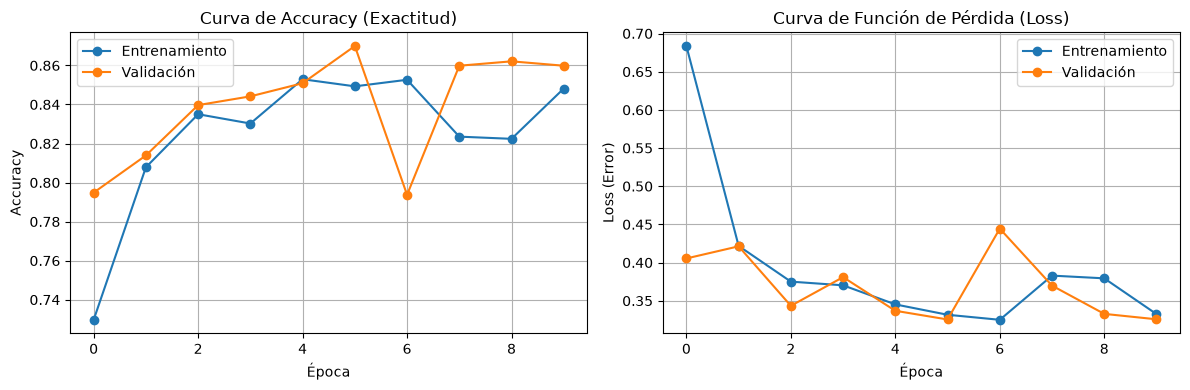


Generando predicciones en el set de validación...

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

   buildings       0.87      0.83      0.85       431
      forest       0.85      0.89      0.87       461

    accuracy                           0.86       892
   macro avg       0.86      0.86      0.86       892
weighted avg       0.86      0.86      0.86       892


--- MATRIZ DE CONFUSIÓN ---


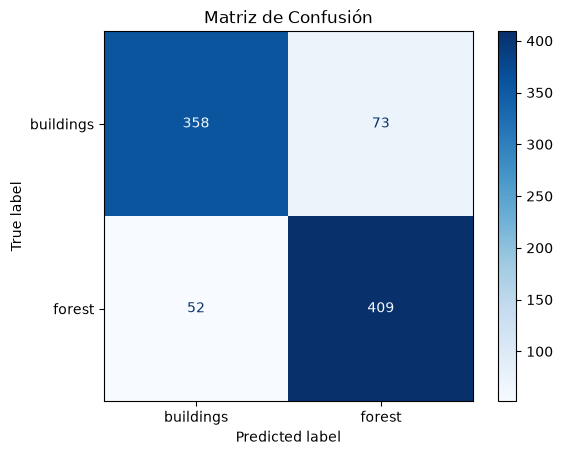

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. GRAFICAR LAS CURVAS DE APRENDIZAJE (Accuracy y Loss)
plt.figure(figsize=(12, 4))

# Gráfico de Accuracy (Qué tan bien clasifica)
plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='Entrenamiento', marker='o')
plt.plot(historial.history['val_accuracy'], label='Validación', marker='o')
plt.title('Curva de Accuracy (Exactitud)')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Gráfico de Loss (El error que comete)
plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='Entrenamiento', marker='o')
plt.plot(historial.history['val_loss'], label='Validación', marker='o')
plt.title('Curva de Función de Pérdida (Loss)')
plt.xlabel('Época')
plt.ylabel('Loss (Error)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show() # ¡Guarda esta imagen para tu informe!

# 2. GENERAR PREDICCIONES PARA LAS MÉTRICAS
print("\nGenerando predicciones en el set de validación...")
y_true = []
y_pred_probs = []

# Extraemos las imágenes de prueba y hacemos que el modelo trate de adivinar
for images, labels in val_dataset:
    y_true.extend(labels.numpy())
    preds = modelo_mlp.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)

# Si la probabilidad es mayor a 0.5, decimos que es la clase 1 (forest), si no, clase 0 (buildings)
y_pred = (y_pred_probs > 0.5).astype(int)

# 3. REPORTE DE CLASIFICACIÓN (Accuracy, Precision, Recall, F1-Score)
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 4. MATRIZ DE CONFUSIÓN
print("\n--- MATRIZ DE CONFUSIÓN ---")
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.show()


Buscando ejemplos mal clasificados...


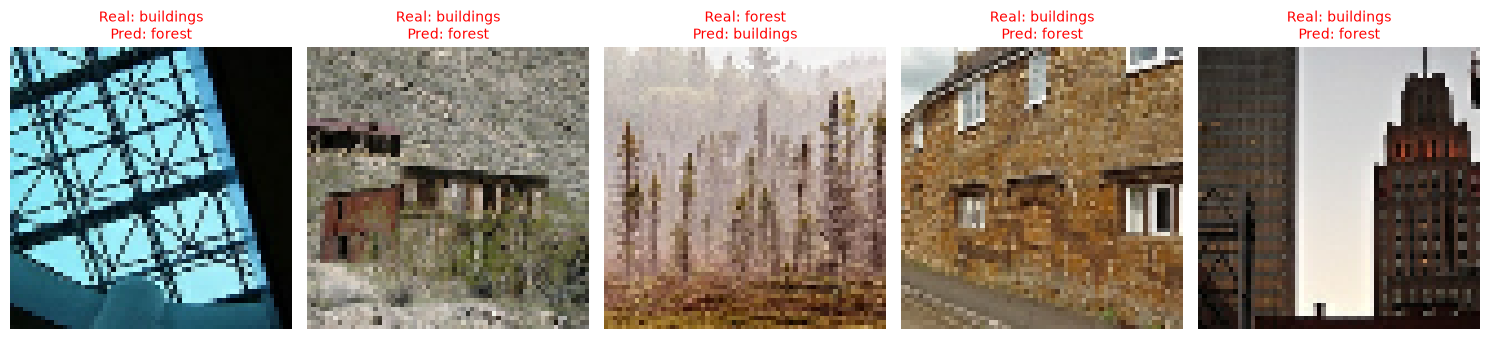

In [7]:
# 5. ANÁLISIS DE ERRORES: Mostramos algunas imágenes mal clasificadas
print("\nBuscando ejemplos mal clasificados...")

plt.figure(figsize=(15, 4))
errores_encontrados = 0

# Buscamos en los lotes de validación
for images, labels in val_dataset:
    # Hacemos las predicciones del lote
    preds = modelo_mlp.predict(images, verbose=0)
    preds_clases = (preds > 0.5).astype(int).flatten()
    etiquetas_reales = labels.numpy()
    
    # Comparamos la predicción con la realidad
    for i in range(len(etiquetas_reales)):
        if preds_clases[i] != etiquetas_reales[i]: # ¡Aquí hay un error!
            ax = plt.subplot(1, 5, errores_encontrados + 1)
            plt.imshow(images[i].numpy())
            clase_real = class_names[etiquetas_reales[i]]
            clase_pred = class_names[preds_clases[i]]
            plt.title(f"Real: {clase_real}\nPred: {clase_pred}", fontsize=10, color='red')
            plt.axis("off")
            errores_encontrados += 1
        
        if errores_encontrados == 5: # Solo mostraremos 5 para el ejemplo
            break
    if errores_encontrados == 5:
        break

plt.tight_layout()
plt.show()